In [1]:
import pandas as pd 
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.metrics import  classification_report
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_curve
from sklearn.metrics import roc_auc_score
from sklearn.metrics import precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error,r2_score
from sklearn.linear_model import Ridge

print("Libararies Exported")

Libararies Exported


Load cleaned_data.csv from Part 1.

In [2]:
df=pd.read_csv("../Data/cleaned_data.csv")
print("Loaded csv file successfully!")
print(f"First 5 rows:\n{df.head(5)}")
print(f"Datatypes:\n{df.dtypes}")
print(f"Shape of Dataframe:\n{df.shape}")
print(f"Null value counts:\n{df.isnull().sum()}")
print(f"Null value percentage:\n{round((df.isnull().sum() / df.shape[0] )* 100,2)}")

Loaded csv file successfully!
First 5 rows:
        City        Date  season AQI_Bucket  avg_temp  min_temp  max_temp  \
0  Ahmedabad  2018-01-01  Winter       Poor      20.3      10.8      27.2   
1  Ahmedabad  2018-01-02  Winter       Poor      19.8      12.2      26.0   
2  Ahmedabad  2018-01-03  Winter       Poor      19.5      12.5      26.0   
3  Ahmedabad  2018-01-04  Winter     Severe      19.6      10.5      28.0   
4  Ahmedabad  2018-01-05  Winter     Severe      19.5       8.6      27.0   

   wind_speed  air_pressure    AQI   ONI  
0         5.4        1011.8  278.0 -0.77  
1         8.5        1012.5  256.0 -0.77  
2         8.3        1013.3  300.0 -0.77  
3         4.1        1013.7  532.0 -0.77  
4         3.0        1012.8  534.0 -0.77  
Datatypes:
City             object
Date             object
season           object
AQI_Bucket       object
avg_temp        float64
min_temp        float64
max_temp        float64
wind_speed      float64
air_pressure    float64
AQI     

Task 2 Encoding Categroical FIelds

In [3]:

risk_mapping = {
    'Good': 0,
    'Satisfactory': 0,
    'Moderate': 0,
    'Poor': 1,
    'Very Poor': 1,
    'Severe': 1
}
# df["AQI_Bucket"].unique()

  
    
X=df.drop(columns=['Date','AQI','AQI_Bucket'])
y_reg=df["AQI"]
y_clf=df["AQI_Bucket"].map(risk_mapping)

print("Feature and Label classifications are done and definitions provided in README file ")
# print(X)
# print(y_reg)
# print(y_clf)

Feature and Label classifications are done and definitions provided in README file 


In [4]:
#Checking
print(X)
print(y_reg)
print(y_clf)

                City   season  avg_temp  min_temp  max_temp  wind_speed  \
0          Ahmedabad   Winter    20.300     10.80     27.20         5.4   
1          Ahmedabad   Winter    19.800     12.20     26.00         8.5   
2          Ahmedabad   Winter    19.500     12.50     26.00         8.3   
3          Ahmedabad   Winter    19.600     10.50     28.00         4.1   
4          Ahmedabad   Winter    19.500      8.60     27.00         3.0   
...              ...      ...       ...       ...       ...         ...   
13147  Visakhapatnam   Summer    30.450     26.55     33.95        10.9   
13148  Visakhapatnam   Summer    30.325     27.20     33.95        10.7   
13149  Visakhapatnam   Summer    30.250     27.35     34.30         8.0   
13150  Visakhapatnam   Summer    30.225     26.70     34.35        10.5   
13151  Visakhapatnam  Monsoon    28.675     25.80     34.05        10.3   

       air_pressure   ONI  
0            1011.8 -0.77  
1            1012.5 -0.77  
2            10

In [5]:
def enso_category(oni):
    if oni>=0.5:
        return "EL Nino"
    elif oni <=-0.5:
        return "La Nina"
    else: 
        return "Neutral"
X["ENSO_Category"]=X["ONI"].apply(enso_category)

X=pd.get_dummies(X,columns=['City','season','ENSO_Category'],drop_first=True)
print("Categorical Feature encoding completed!")

Categorical Feature encoding completed!


In [6]:
#Checking
# print(X.columns.tolist())

Task3 _ Leak Free Tarin & test split

In [7]:
X_train_reg,X_test_reg,y_train_reg,y_test_reg=train_test_split(X,y_reg,test_size=0.2,random_state=42)
X_train_clf,X_test_clf,y_train_clf,y_test_clf=train_test_split(X,y_clf,test_size=0.2,random_state=42)

scaler_reg=StandardScaler()
X_train_reg_scaled=scaler_reg.fit_transform(X_train_reg)
X_test_reg_scaled=scaler_reg.transform(X_test_reg)

scaler_clf=StandardScaler()
X_train_clf_scaled=scaler_clf.fit_transform(X_train_clf)
X_test_clf_scaled=scaler_clf.transform(X_test_clf)

print("Training and testings set are splitted and scaled accrodingly")




Training and testings set are splitted and scaled accrodingly


Task 4 - Regression Model(Linear Regression )

In [8]:
linear_model=LinearRegression()
linear_model.fit(X_train_reg_scaled,y_train_reg)
print("Linear Model Trained ")
y_pred_reg=linear_model.predict(X_test_reg_scaled)
print("Linear Model Predicted")

linear_mse=mean_squared_error(y_test_reg,y_pred_reg)
linear_r2=r2_score(y_test_reg,y_pred_reg)

print(f"Linear MSE:{round(linear_mse,2)}")
print(f"Linear R2 score:{round(linear_r2,2)}")
#Refered documentation how to print comaparsion in Readble format
coefficient_linear=pd.DataFrame({"Feature":X.columns,"Coefficient":linear_model.coef_})

print(f"Coefficeint:{coefficient_linear}")

print("Identifying 3 large coefficents:")
coefficient_linear["AbsCoefficient"] = coefficient_linear["Coefficient"].abs()

top3_features = coefficient_linear.sort_values("AbsCoefficient", ascending=False).head(3)


print("Top 3 Features with Largest Absolute Coefficients:")
print(top3_features)
ridge_model = Ridge(alpha=1.0)

ridge_model.fit(X_train_reg_scaled, y_train_reg)
print("Ridge model Trained")
ridge_pred = ridge_model.predict(X_test_reg_scaled)
print("RIdge model predicted")
ridge_mse=mean_squared_error(y_test_reg,ridge_pred)
ridge_r2=r2_score(y_test_reg,ridge_pred)
print(f"RidegMSE:{round(ridge_mse,2)}")
print(f"Ridge R2 score:{round(ridge_r2,2)}")

comparison=pd.DataFrame({"Model":["Linear Regression","Ridge Regression"],"MSE":[round(linear_mse,2),round(ridge_mse,2)],
                         "R2 score":[round(linear_r2,2),round(ridge_r2,2)]})
print(comparison)

Linear Model Trained 
Linear Model Predicted
Linear MSE:9308.28
Linear R2 score:0.61
Coefficeint:                    Feature  Coefficient
0                  avg_temp   -16.125363
1                  min_temp   -41.019521
2                  max_temp    34.213021
3                wind_speed   -14.396526
4              air_pressure     9.528357
5                       ONI    11.842221
6             City_Amritsar  -101.515582
7            City_Bengaluru  -101.044455
8               City_Bhopal   -53.670896
9           City_Chandigarh   -58.988098
10             City_Chennai   -91.461617
11          City_Coimbatore   -63.974635
12               City_Delhi   -72.131127
13           City_Ernakulam   -37.490605
14            City_Guwahati   -66.913400
15           City_Hyderabad  -100.149287
16              City_Jaipur   -95.939576
17             City_Kolkata   -75.458833
18             City_Lucknow   -76.791355
19              City_Mumbai   -82.687709
20               City_Patna   -70.840009
2

In [9]:
#checking
from sklearn.metrics import r2_score

# Training performance
train_pred = linear_model.predict(X_train_reg_scaled)
train_r2 = r2_score(y_train_reg, train_pred)

# Testing performance
test_r2 = r2_score(y_test_reg, y_pred_reg)

print(f"Training R² : {round(train_r2,4)}")
print(f"Testing R²  : {round(test_r2,4)}")

Training R² : 0.5892
Testing R²  : 0.6112


Task 5 - Classification Model

In [10]:
print("Imbalace address")
print(y_train_clf.value_counts())


print((y_train_clf.value_counts(normalize=True) * 100).round(2))


Imbalace address
AQI_Bucket
0    8337
1    2184
Name: count, dtype: int64
AQI_Bucket
0    79.24
1    20.76
Name: proportion, dtype: float64


Logistic Regression model trained
Logistic Model predicts and probabilities 

Confusion Matrix:
      0    1
0  1871  230
1    63  467

Accuracy: 0.8886

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.89      0.93      2101
           1       0.67      0.88      0.76       530

    accuracy                           0.89      2631
   macro avg       0.82      0.89      0.84      2631
weighted avg       0.91      0.89      0.89      2631


AUC Score: 0.9504


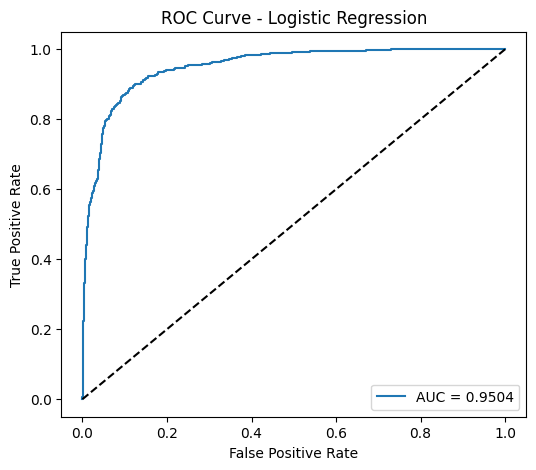

In [11]:


logistic_model = LogisticRegression( max_iter=1000,class_weight="balanced"
)

logistic_model.fit(X_train_clf_scaled, y_train_clf)

print("Logistic Regression model trained")

y_pred_clf = logistic_model.predict(X_test_clf_scaled)

y_pred_proba = logistic_model.predict_proba(X_test_clf_scaled)[:, 1]
print("Logistic Model predicts and probabilities ")

cm = confusion_matrix(y_test_clf, y_pred_clf)
print("\nConfusion Matrix:")
print(pd.DataFrame(cm))


accuracy = accuracy_score(y_test_clf, y_pred_clf)
print(f"\nAccuracy: {round(accuracy,4)}")

print("\nClassification Report:")
print(classification_report(y_test_clf, y_pred_clf))

fpr, tpr, thresholds = roc_curve(y_test_clf, y_pred_proba)
auc_score = roc_auc_score(y_test_clf, y_pred_proba)
print(f"\nAUC Score: {round(auc_score,4)}")
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {round(auc_score,4)}")
plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend(loc="lower right")
plt.savefig("../outputs/Roc_curve.png", bbox_inches="tight")
plt.show()

Task 5 b- Decision threshold

In [12]:
thresholds = [0.30, 0.40, 0.50, 0.60, 0.70]

results = []

for threshold in thresholds:
    
    y_pred_threshold = (y_pred_proba >= threshold).astype(int)

    precision = precision_score(y_test_clf, y_pred_threshold)
    recall = recall_score(y_test_clf, y_pred_threshold)
    f1 = f1_score(y_test_clf, y_pred_threshold)

    results.append([threshold,round(precision, 3),round(recall, 3),round(f1, 3)])

threshold_results = pd.DataFrame(
    results,
    columns=["Threshold", "Precision", "Recall", "F1"]
)

print(threshold_results)

   Threshold  Precision  Recall     F1
0        0.3      0.506   0.947  0.659
1        0.4      0.599   0.923  0.726
2        0.5      0.670   0.881  0.761
3        0.6      0.709   0.845  0.771
4        0.7      0.770   0.800  0.784


Task 6 -Regularization

In [13]:
logistic_model_C001 = LogisticRegression(
    C=0.01,
    max_iter=1000,
    class_weight="balanced"
)

logistic_model_C001.fit(X_train_clf_scaled, y_train_clf)


y_pred_c001 = logistic_model_C001.predict(X_test_clf_scaled)
y_pred_proba_c001 = logistic_model_C001.predict_proba(X_test_clf_scaled)[:, 1]


precision_c001 = precision_score(y_test_clf, y_pred_c001)
recall_c001 = recall_score(y_test_clf, y_pred_c001)
auc_c001 = roc_auc_score(y_test_clf, y_pred_proba_c001)


precision_base = precision_score(y_test_clf, y_pred_clf)
recall_base = recall_score(y_test_clf, y_pred_clf)
auc_base = roc_auc_score(y_test_clf, y_pred_proba)

# Comparison Table
comparison = pd.DataFrame({
    "Model": ["Logistic Regression (C=1.0)", "Logistic Regression (C=0.01)"],
    "Precision": [round(precision_base, 3), round(precision_c001, 3)],
    "Recall": [round(recall_base, 3), round(recall_c001, 3)],
    "AUC": [round(auc_base, 3), round(auc_c001, 3)]
})

print(comparison)

                          Model  Precision  Recall    AUC
0   Logistic Regression (C=1.0)       0.67   0.881  0.950
1  Logistic Regression (C=0.01)       0.63   0.874  0.943


Task 7 - Bootstrap

In [14]:
auc_difference = []

np.random.seed(42)

for i in range(500):

    indices = np.random.choice(
        len(y_test_clf),
        size=len(y_test_clf),
        replace=True
    )

    y_bootstrap = y_test_clf.iloc[indices]

    proba_c1 = y_pred_proba[indices]
    proba_c001 = y_pred_proba_c001[indices]

    auc_c1 = roc_auc_score(y_bootstrap, proba_c1)
    auc_c001 = roc_auc_score(y_bootstrap, proba_c001)

    auc_difference.append(auc_c1 - auc_c001)


mean_diff = np.mean(auc_difference)
lower_ci = np.percentile(auc_difference, 2.5)
upper_ci = np.percentile(auc_difference, 97.5)

print(f"Mean AUC Difference : {round(mean_diff,4)}")
print(f"95% Confidence Interval : [{round(lower_ci,4)}, {round(upper_ci,4)}]")

Mean AUC Difference : 0.0078
95% Confidence Interval : [0.0046, 0.0107]
